---
## Section 1 — Acquisition et Visualisation des Données

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import linregress
from scipy import integrate
from scipy.integrate import quad
from scipy.optimize import bisect
import math
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11,
                     'axes.grid': True, 'grid.alpha': 0.3})

np.random.seed(42)

# ── Paramètres Weibull ──────────────────────────────────────────
beta = 2.5   # paramètre de forme  (β > 1 ⟹ vieillissement)
eta  = 3.0   # paramètre d'échelle (k·h)
N    = 1000  # taille du parc

print(f"Paramètres choisis : β = {beta}, η = {eta} k·h")

Paramètres choisis : β = 2.5, η = 3.0 k·h


### Q1 — Génération de l'échantillon Weibull

In [ ]:
# Génération de 1000 réalisations d'une loi Weibull(β, η)
# Si X ~ Weibull(β) standard, alors T = η·X ~ Weibull(β, η)
T = eta * np.random.weibull(beta, N)

print(f"Taille de l'échantillon : {N}")
print(f"Moyenne empirique       : {T.mean():.4f} k·h  ({T.mean()*1000:.0f} heures)")
print(f"Écart-type empirique    : {T.std():.4f} k·h")
print(f"Min / Max               : {T.min():.4f} / {T.max():.4f} k·h")
print(f"Quantile 10%            : {np.percentile(T, 10):.4f} k·h")
print(f"Médiane                 : {np.median(T):.4f} k·h")
print(f"Quantile 90%            : {np.percentile(T, 90):.4f} k·h")

Taille de l'échantillon : 1000
Moyenne empirique       : 2.6244 k·h  (2624 heures)
Écart-type empirique    : 1.1391 k·h
Min / Max               : 0.3498 / 6.9512 k·h
Quantile 10%            : 1.1826 k·h
Médiane                 : 2.5814 k·h
Quantile 90%            : 4.1852 k·h


### Q2 — Histogramme des durées de vie

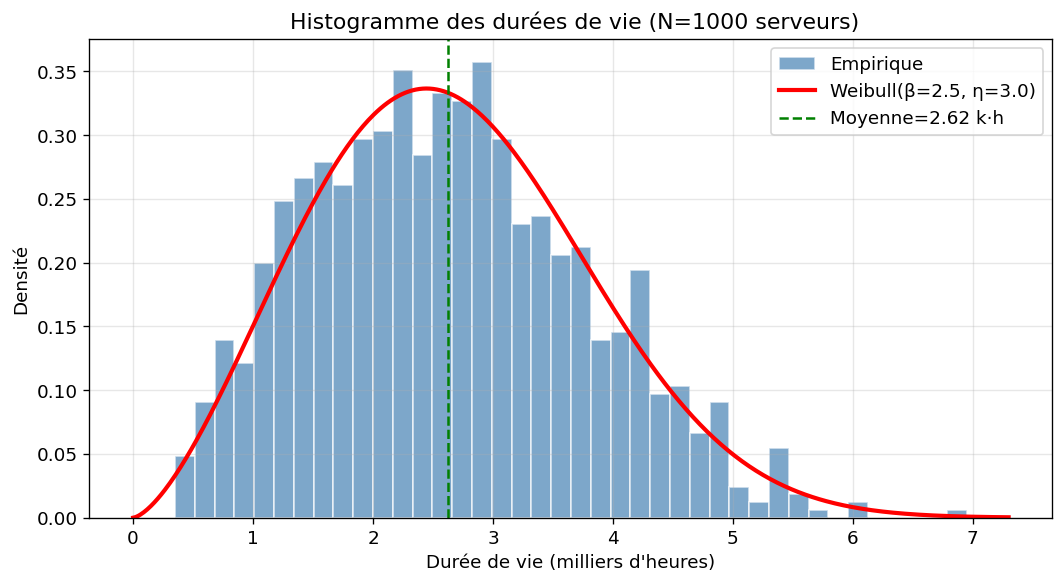

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(T, bins=40, density=True, color='steelblue', alpha=0.7,
        edgecolor='white', label='Empirique')

# Densité théorique Weibull
t_range = np.linspace(1e-3, T.max()*1.05, 500)
f_theo  = (beta/eta) * (t_range/eta)**(beta-1) * np.exp(-(t_range/eta)**beta)
ax.plot(t_range, f_theo, 'r-', lw=2.5, label=f'Weibull(β={beta}, η={eta})')

ax.axvline(T.mean(), color='green', ls='--', lw=1.5, label=f'Moyenne={T.mean():.2f} k·h')
ax.set_xlabel("Durée de vie (milliers d'heures)")
ax.set_ylabel("Densité")
ax.set_title(" Histogramme des durées de vie (N=1000 serveurs)")
ax.legend()
plt.tight_layout()
plt.show()

### Q3 — Courbe de fiabilité empirique $\hat{R}(t)$

   STATISTIQUES DE R_hat(t) — Fiabilité empirique

  t = 1.0 kh :
    R_hat(t)  empirique  = 0.9360
    R(t)      théorique  = 0.9379
    Biais     = R_hat - R = -0.0019  (≈ 0 → sans biais ✓)
    Var(R_hat)= R(1-R)/n  = 0.000058
    IC 95%%   = [0.9208 ; 0.9512]

  t = 2.0 kh :
    R_hat(t)  empirique  = 0.6780
    R(t)      théorique  = 0.6957
    Biais     = R_hat - R = -0.0177  (≈ 0 → sans biais ✓)
    Var(R_hat)= R(1-R)/n  = 0.000212
    IC 95%%   = [0.6490 ; 0.7070]

  t = 3.0 kh :
    R_hat(t)  empirique  = 0.3520
    R(t)      théorique  = 0.3679
    Biais     = R_hat - R = -0.0159  (≈ 0 → sans biais ✓)
    Var(R_hat)= R(1-R)/n  = 0.000233
    IC 95%%   = [0.3224 ; 0.3816]

  t = 3.0 kh :
    R_hat(t)  empirique  = 0.3520
    R(t)      théorique  = 0.3679
    Biais     = R_hat - R = -0.0159  (≈ 0 → sans biais ✓)
    Var(R_hat)= R(1-R)/n  = 0.000233
    IC 95%%   = [0.3224 ; 0.3816]

   ERREUR GLOBALE
  MSE (erreur quadratique moyenne) = 0.000083
  MAE (erreur absolue moyenne)   

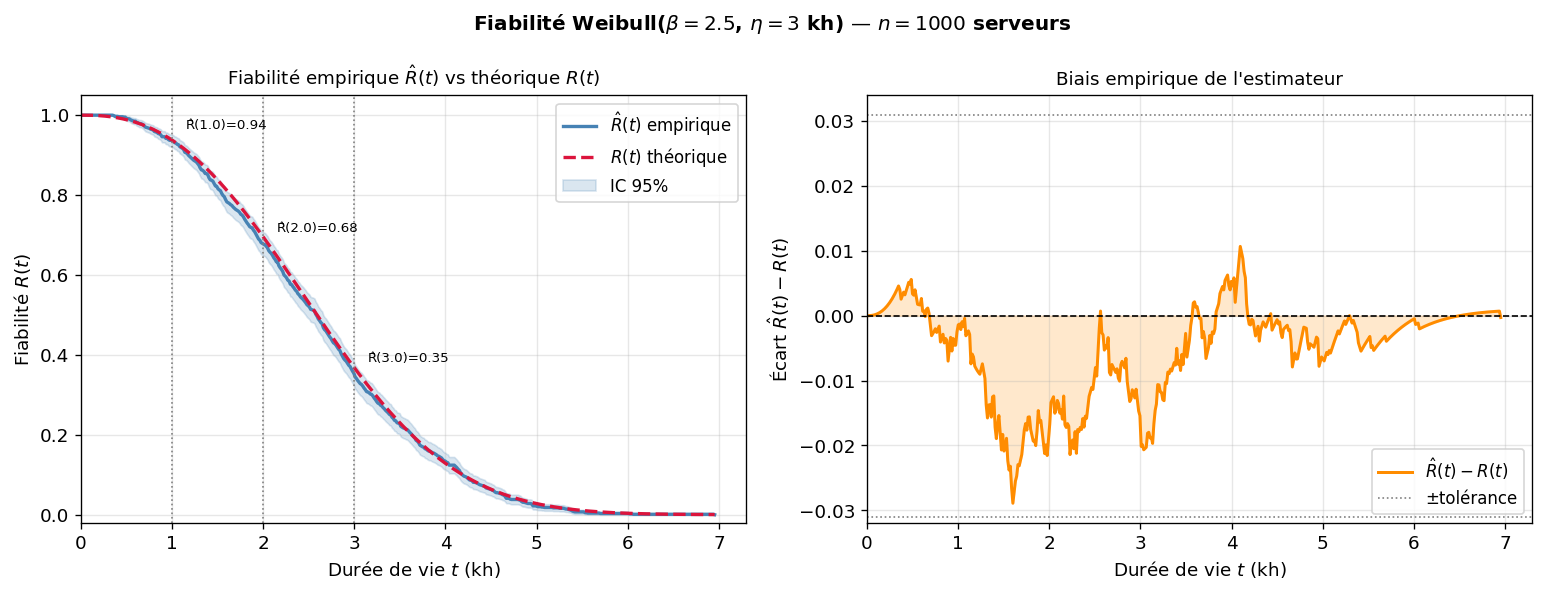

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import stats

beta = 2.5
eta  = 3.0
N    = 1000
np.random.seed(42)
T = eta * np.random.weibull(beta, N)

# ── Grille de temps ────────────────────────────────────────────
t_grid = np.linspace(0, T.max(), 500)

# ── Fiabilité empirique R_hat(t) ───────────────────────────────
R_emp  = np.array([np.mean(T > t) for t in t_grid])

# ── Fiabilité théorique R(t) = exp(-(t/η)^β) ──────────────────
R_theo = np.exp(-(t_grid / eta)**beta)

# ══════════════════════════════════════════════════════════════
# STATISTIQUES COMPLÈTES
# ══════════════════════════════════════════════════════════════
print("=" * 55)
print("   STATISTIQUES DE R_hat(t) — Fiabilité empirique")
print("=" * 55)

# Points d'intérêt : t = 1, 2, 3 kh
for t_val in [1.0, 2.0, 3.0, eta]:
    R_e = np.mean(T > t_val)
    R_t = np.exp(-(t_val / eta)**beta)
    biais = R_e - R_t
    var   = R_t * (1 - R_t) / N          # variance théorique
    ic_lo = R_e - 1.96 * np.sqrt(R_e*(1-R_e)/N)  # IC 95%
    ic_hi = R_e + 1.96 * np.sqrt(R_e*(1-R_e)/N)

    print(f"\n  t = {t_val:.1f} kh :")
    print(f"    R_hat(t)  empirique  = {R_e:.4f}")
    print(f"    R(t)      théorique  = {R_t:.4f}")
    print(f"    Biais     = R_hat - R = {biais:+.4f}  (≈ 0 → sans biais ✓)")
    print(f"    Var(R_hat)= R(1-R)/n  = {var:.6f}")
    print(f"    IC 95%%   = [{ic_lo:.4f} ; {ic_hi:.4f}]")

# Vérification globale sans biais (MSE)
print("\n" + "=" * 55)
print("   ERREUR GLOBALE")
print("=" * 55)
MSE = np.mean((R_emp - R_theo)**2)
MAE = np.mean(np.abs(R_emp - R_theo))
print(f"  MSE (erreur quadratique moyenne) = {MSE:.6f}")
print(f"  MAE (erreur absolue moyenne)     = {MAE:.4f}")
print(f"  Max |R_hat - R|                  = {np.max(np.abs(R_emp-R_theo)):.4f}")

# ══════════════════════════════════════════════════════════════
# FIGURE
# ══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Graphe 1 : Courbes de fiabilité ───────────────────────────
ax = axes[0]
ax.plot(t_grid, R_emp,  color='steelblue', lw=2,   label=r'$\hat{R}(t)$ empirique')
ax.plot(t_grid, R_theo, color='crimson',   lw=2, ls='--', label=r'$R(t)$ théorique')

# Bande de confiance à 95%
se = np.sqrt(R_emp * (1 - R_emp) / N)
ax.fill_between(t_grid, R_emp - 1.96*se, R_emp + 1.96*se,
                alpha=0.2, color='steelblue', label='IC 95%')

# Lignes verticales aux points d'intérêt
for t_val, col in zip([1.0, 2.0, 3.0], ['gray','gray','gray']):
    R_e = np.mean(T > t_val)
    ax.axvline(t_val, color=col, ls=':', lw=1)
    ax.annotate(f'R̂({t_val})={R_e:.2f}', xy=(t_val, R_e),
                xytext=(t_val+0.15, R_e+0.03), fontsize=8)

ax.set_xlabel("Durée de vie $t$ (kh)", fontsize=11)
ax.set_ylabel("Fiabilité $R(t)$", fontsize=11)
ax.set_title(r"Fiabilité empirique $\hat{R}(t)$ vs théorique $R(t)$", fontsize=11)
ax.legend(fontsize=10)
ax.set_xlim(0)
ax.set_ylim(-0.02, 1.05)

# ── Graphe 2 : Écart R_hat - R (biais) ───────────────────────
ax2 = axes[1]
ecart = R_emp - R_theo
ax2.plot(t_grid, ecart, color='darkorange', lw=1.8, label=r'$\hat{R}(t) - R(t)$')
ax2.axhline(0, color='black', lw=1, ls='--')
ax2.fill_between(t_grid, ecart, 0, alpha=0.2, color='darkorange')

# Bande ±1.96*se (IC du biais)
ax2.axhline(+1.96/np.sqrt(N)*0.5, color='gray', ls=':', lw=1, label='±tolérance')
ax2.axhline(-1.96/np.sqrt(N)*0.5, color='gray', ls=':', lw=1)

ax2.set_xlabel("Durée de vie $t$ (kh)", fontsize=11)
ax2.set_ylabel(r"Écart $\hat{R}(t) - R(t)$", fontsize=11)
ax2.set_title("Biais empirique de l'estimateur", fontsize=11)
ax2.legend(fontsize=10)
ax2.set_xlim(0)

plt.suptitle(r"Fiabilité Weibull($\beta=2.5$, $\eta=3$ kh) — $n=1000$ serveurs",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Q4 — Taux de défaillance empirique $\hat{\lambda}(t)$

   TAUX DE DÉFAILLANCE — Statistiques aux points clés

  t = 1.0 kh :
    λ_hat(t) empirique = 0.1451 kh⁻¹
    λ(t)    théorique  = 0.1600 kh⁻¹
    Biais              = -0.0149

  t = 2.0 kh :
    λ_hat(t) empirique = 0.4423 kh⁻¹
    λ(t)    théorique  = 0.4536 kh⁻¹
    Biais              = -0.0113

  t = 3.0 kh :
    λ_hat(t) empirique = 0.9666 kh⁻¹
    λ(t)    théorique  = 0.8339 kh⁻¹
    Biais              = +0.1327

  MSE = 0.046215
  MAE = 0.1190 kh⁻¹


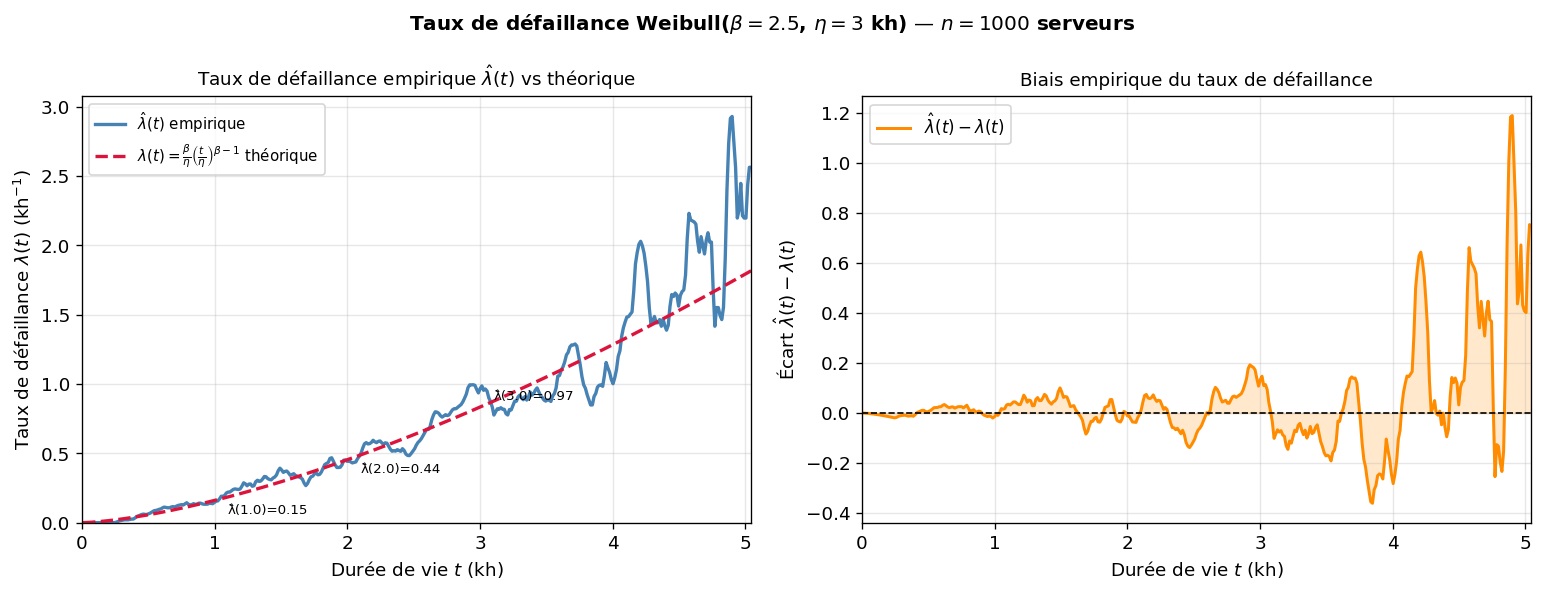

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

# ── Grille limitée là où R_hat est fiable ───────────────────────
t_grid = np.linspace(0.01, 6.5, 500)

# ── 1. Fiabilité empirique ──────────────────────────────────────
R_emp = np.array([np.mean(T > t) for t in t_grid])

# ── 2. Masque : garder uniquement là où R_hat est fiable ────────
masque = R_emp >= 0.02
t_plot = t_grid[masque]
R_plot = R_emp[masque]

# ── 3. Densité empirique par différences finies + lissage ───────
f_brut  = -np.gradient(R_plot, t_plot)
f_brut  = np.clip(f_brut, 1e-8, None)
f_lisse = uniform_filter1d(f_brut, size=15)
f_lisse = np.clip(f_lisse, 1e-8, None)

# ── 4. Taux de défaillance empirique ───────────────────────────
lambda_emp  = f_lisse / R_plot

# ── 5. Taux théorique ──────────────────────────────────────────
lambda_theo = (beta / eta) * (t_plot / eta)**(beta - 1)

# ══════════════════════════════════════════════════════════════
# STATISTIQUES
# ══════════════════════════════════════════════════════════════
print("=" * 55)
print("   TAUX DE DÉFAILLANCE — Statistiques aux points clés")
print("=" * 55)
for t_val in [1.0, 2.0, 3.0]:
    idx   = np.argmin(np.abs(t_plot - t_val))
    lam_e = lambda_emp[idx]
    lam_t = lambda_theo[idx]
    print(f"\n  t = {t_val} kh :")
    print(f"    λ_hat(t) empirique = {lam_e:.4f} kh⁻¹")
    print(f"    λ(t)    théorique  = {lam_t:.4f} kh⁻¹")
    print(f"    Biais              = {lam_e - lam_t:+.4f}")

MSE = np.mean((lambda_emp - lambda_theo)**2)
MAE = np.mean(np.abs(lambda_emp - lambda_theo))
print(f"\n  MSE = {MSE:.6f}")
print(f"  MAE = {MAE:.4f} kh⁻¹")

# ══════════════════════════════════════════════════════════════
# FIGURE
# ══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Graphe gauche ─────────────────────────────────────────────
ax = axes[0]
ax.plot(t_plot, lambda_emp,  color='steelblue', lw=2,
        label=r'$\hat{\lambda}(t)$ empirique')
ax.plot(t_plot, lambda_theo, color='crimson', lw=2, ls='--',
        label=r'$\lambda(t)=\frac{\beta}{\eta}\left(\frac{t}{\eta}\right)^{\beta-1}$ théorique')

# Annotations aux points clés
for t_val in [1.0, 2.0, 3.0]:
    idx = np.argmin(np.abs(t_plot - t_val))
    ax.annotate(f'λ̂({t_val})={lambda_emp[idx]:.2f}',
                xy=(t_val, lambda_emp[idx]),
                xytext=(t_val + 0.1, lambda_emp[idx] - 0.08),
                fontsize=8)

ax.set_xlabel(r'Durée de vie $t$ (kh)', fontsize=11)
ax.set_ylabel(r'Taux de défaillance $\lambda(t)$ (kh$^{-1}$)', fontsize=11)
ax.set_title(r'Taux de défaillance empirique $\hat{\lambda}(t)$ vs théorique',
             fontsize=11)
ax.legend(fontsize=9)
ax.set_xlim(0, t_plot[-1])
ax.set_ylim(0)

# ── Graphe droit ──────────────────────────────────────────────
ax2 = axes[1]
ecart = lambda_emp - lambda_theo
ax2.plot(t_plot, ecart, color='darkorange', lw=1.8,
         label=r'$\hat{\lambda}(t) - \lambda(t)$')
ax2.axhline(0, color='black', lw=1, ls='--')
ax2.fill_between(t_plot, ecart, 0, alpha=0.2, color='darkorange')
ax2.set_xlabel(r'Durée de vie $t$ (kh)', fontsize=11)
ax2.set_ylabel(r'Écart $\hat{\lambda}(t) - \lambda(t)$', fontsize=11)
ax2.set_title("Biais empirique du taux de défaillance", fontsize=11)
ax2.legend(fontsize=10)
ax2.set_xlim(0, t_plot[-1])

plt.suptitle(
    r'Taux de défaillance Weibull($\beta=2.5$, $\eta=3$ kh) — $n=1000$ serveurs',
    fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
# Section 2 - Estimation des Paramètres("PapierdeWeibull")

### Q1 - Démonstration de la formule demandé


$\textit{Soit,}$

\begin{align}
R(t) &= \exp\left(-\left(\frac{t}{\eta}\right)^\beta\right)\\[10pt]
-\ln\big(R(t)\big) &= \left(\frac{t}{\eta}\right)^\beta \textit{,par application du logarithme népérien}\\[10pt]
\ln\big(-\ln(R(t))\big) &= \beta \ln(t) - \beta \ln(\eta)\quad \textit{,par application du logarithme népérien} \\[10pt]
\end{align}



#####$\textit{D'où la relation linéaire entre $\ln(-\ln(R(t)))$ et $\ln(t)$.}$

### Q2 - Détermination (à partir d'une régression linéaire) des paramètres $\beta$ et $\eta$ de la loi de Weibull

In [ ]:
# --- Fiabilité empirique via estimateur de Kaplan-Meier simplifié ---
T_sorted = np.sort(T)
i_ranks  = np.arange(1, N + 1)

# R_hat(t_i) = (N - i) / N  (estimateur empirique)
R_hat = (N - i_ranks) / N

# On exclut R_hat == 0 pour éviter ln(0)
mask   = R_hat > 0
t_km   = T_sorted[mask]
R_km   = R_hat[mask]

# Transformation linéaire du papier de Weibull
def linear_regression(x, y):
    x = np.array(x)
    y = np.array(y)

    x_mean = np.mean(x)
    y_mean = np.mean(y)

    a = np.sum((x - x_mean)*(y - y_mean)) / np.sum((x - x_mean)**2)
    b = y_mean - a * x_mean

    return a, b

X = np.log(t_km)                    # ln(t)
Y = np.log(-np.log(R_km))          # ln(-ln(R(t)))

# --- Régression linéaire ---
slope, intercept = linear_regression(X, Y)

beta_est = slope
eta_est  = np.exp(-intercept / beta_est)

print(f"\nRésultats de la régression linéaire :")
print(f"  Pente (β estimé)         = {beta_est:.4f}  (vrai : {beta})")
print(f"  Ordonnée à l'origine     = {intercept:.4f}")
print(f"  η estimé                 = {eta_est:.4f}  (vrai : {eta})")

# Calcul de R²
y_pred = slope * X + intercept
ss_res = np.sum((Y - y_pred)**2)
ss_tot = np.sum((Y - np.mean(Y))**2)
r_squared = 1 - ss_res / ss_tot
print(f"  Coefficient de détermination R² = {r_squared:.4f}")


Résultats de la régression linéaire :
  Pente (β estimé)         = 2.5072  (vrai : 2.5)
  Ordonnée à l'origine     = -2.7108
  η estimé                 = 2.9483  (vrai : 3.0)
  Coefficient de détermination R² = 0.9953


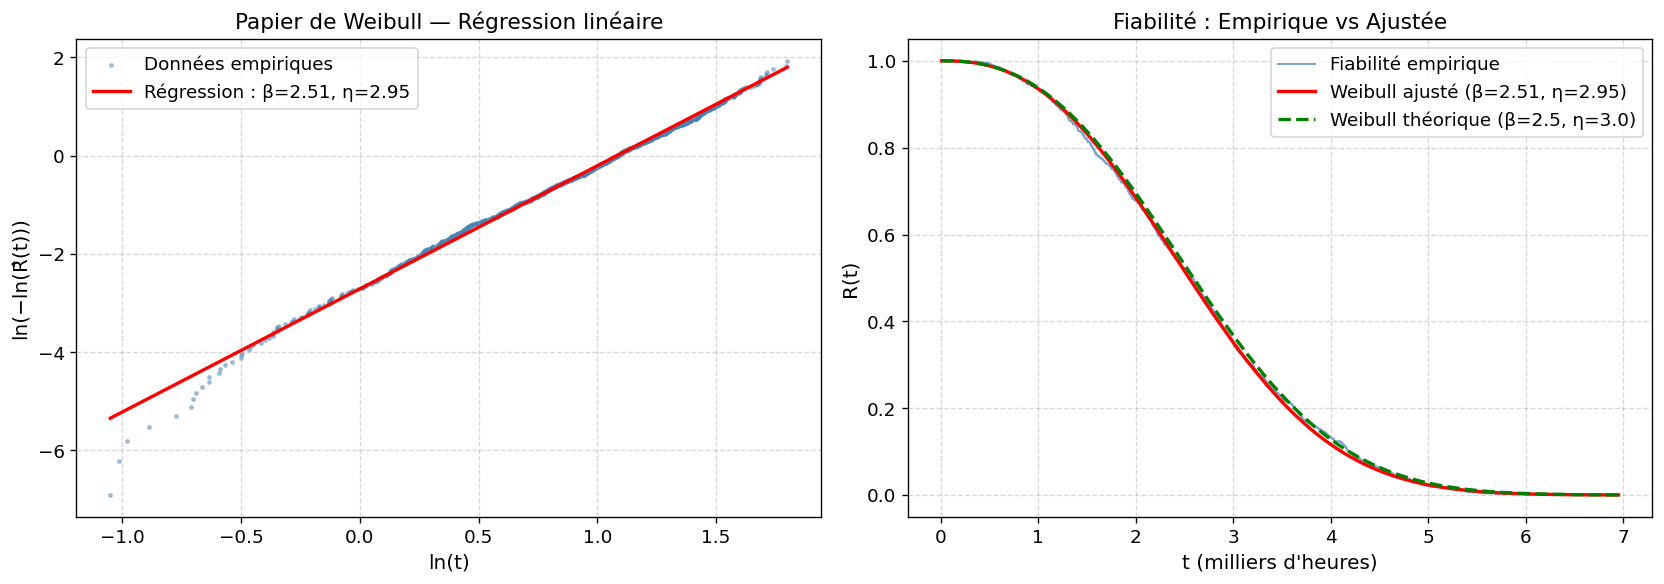

In [ ]:
# VISUALISATION

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -- Graphique 1 : Papier de Weibull (échelle log-log) --
ax = axes[0]
ax.scatter(X, Y, s=4, alpha=0.4, color='steelblue', label='Données empiriques')
X_line = np.linspace(X.min(), X.max(), 200)
Y_line = slope * X_line + intercept
ax.plot(X_line, Y_line, 'r-', lw=2,
        label=f'Régression : β={beta_est:.2f}, η={eta_est:.2f}')
ax.set_xlabel('ln(t)', fontsize=12)
ax.set_ylabel('ln(−ln(R̂(t)))', fontsize=12)
ax.set_title('Papier de Weibull — Régression linéaire', fontsize=13)
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

# -- Graphique 2 : Comparaison fiabilités empirique vs ajustée --
ax2 = axes[1]
t_plot   = np.linspace(0.01, T.max(), 500)
R_weibull_est  = np.exp(-(t_plot / eta_est) ** beta_est)
R_weibull_true = np.exp(-(t_plot / eta) ** beta)

ax2.step(t_km, R_km, where='post', color='steelblue',
         alpha=0.7, lw=1.2, label='Fiabilité empirique')
ax2.plot(t_plot, R_weibull_est,  'r-',  lw=2,
         label=f'Weibull ajusté (β={beta_est:.2f}, η={eta_est:.2f})')
ax2.plot(t_plot, R_weibull_true, 'g--', lw=2,
         label=f'Weibull théorique (β={beta}, η={eta})')
ax2.set_xlabel('t (milliers d\'heures)', fontsize=12)
ax2.set_ylabel('R(t)', fontsize=12)
ax2.set_title('Fiabilité : Empirique vs Ajustée', fontsize=13)
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('papier_weibull.png', dpi=150)
plt.show()

### Q3 -L'analyse de la courbe du taux de fiabilité en fonction du temps (t en milliers d'heures) nous montre une fiabilité assez élevée et stable pour des temps inférieurs à 2200 heures. Après cette étape, la courbe dégringole rapidement pour se retrouver à des taux de fiabilité très faibles, d'où le vieillissement accéléré du parc de serveurs.

# Section 2.5 — Estimation par Maximum de Vraisemblance (MLE)

### Introduction

La méthode du **Maximum de Vraisemblance (MLE)** est l'approche statistique de référence pour estimer les paramètres d'une loi de probabilité. Contrairement à la régression linéaire sur le papier de Weibull (qui transforme les données et introduit un biais lié à la transformation), la MLE maximise directement la fonction de vraisemblance :

$$\mathcal{L}(\beta, \eta \mid t_1, \ldots, t_n) = \prod_{i=1}^{n} \frac{\beta}{\eta}\left(\frac{t_i}{\eta}\right)^{\beta-1} e^{-(t_i/\eta)^\beta}$$

On maximise en pratique la **log-vraisemblance** :

$$\ell(\beta, \eta) = n\ln\beta - n\beta\ln\eta + (\beta-1)\sum_{i=1}^n \ln t_i - \sum_{i=1}^n \left(\frac{t_i}{\eta}\right)^\beta$$

### Dérivation des équations du score

En annulant les dérivées partielles de $\ell$ par rapport à $\beta$ et $\eta$, on obtient le système :

$$\frac{\partial \ell}{\partial \eta} = 0 \implies \hat{\eta} = \left(\frac{1}{n}\sum_{i=1}^n t_i^{\hat{\beta}}\right)^{1/\hat{\beta}}$$

$$\frac{\partial \ell}{\partial \beta} = 0 \implies \frac{1}{\hat{\beta}} + \frac{1}{n}\sum_{i=1}^n \ln t_i - \frac{\sum_{i=1}^n t_i^{\hat{\beta}} \ln t_i}{\sum_{i=1}^n t_i^{\hat{\beta}}} = 0$$

La deuxième équation est **non-linéaire** en $\hat{\beta}$ : on la résout numériquement (méthode de Brent via `scipy.optimize`), puis $\hat{\eta}$ s'en déduit analytiquement.


### Unicité de l'estimateur MLE — Dérivées secondes

Pour s'assurer que $(\hat{\beta}, \hat{\eta})$ est bien un **maximum global**, on vérifie que la matrice hessienne de la log-vraisemblance est **définie négative** en ce point, ce qui revient à montrer que les deux dérivées secondes pures sont strictement négatives et que le déterminant du hessien est strictement positif.

---

**1. Dérivée seconde par rapport à $\beta$ : $\frac{\partial^2 \ell}{\partial \beta^2}$**

On repart de l'équation de score :

$$\frac{\partial \ell}{\partial \beta} = \frac{n}{\beta} + \sum_{i=1}^n \ln t_i - \sum_{i=1}^n \left(\frac{t_i}{\eta}\right)^\beta \ln\left(\frac{t_i}{\eta}\right)$$

En dérivant une seconde fois par rapport à $\beta$ :

$$\frac{\partial^2 \ell}{\partial \beta^2} = -\frac{n}{\beta^2} - \sum_{i=1}^n \left(\frac{t_i}{\eta}\right)^\beta \left[\ln\left(\frac{t_i}{\eta}\right)\right]^2$$

Chaque terme est strictement négatif : $-\frac{n}{\beta^2} < 0$, et chaque terme de la somme est $\leq 0$ (carré). Donc :

$$\boxed{\frac{\partial^2 \ell}{\partial \beta^2} < 0 \quad \forall\, \beta > 0}$$

---

**2. Dérivée seconde par rapport à $\eta$ : $\frac{\partial^2 \ell}{\partial \eta^2}$**

On repart de l'équation de score :

$$\frac{\partial \ell}{\partial \eta} = -\frac{n\beta}{\eta} + \frac{\beta}{\eta^{\beta+1}} \sum_{i=1}^n t_i^\beta$$

En dérivant par rapport à $\eta$ :

$$\frac{\partial^2 \ell}{\partial \eta^2} = \frac{n\beta}{\eta^2} - \frac{\beta(\beta+1)}{\eta^{\beta+2}} \sum_{i=1}^n t_i^\beta$$

En substituant $\hat{\eta}^\beta = \frac{1}{n}\sum_{i=1}^n t_i^\beta$ (condition du premier ordre sur $\eta$) :

$$\frac{\partial^2 \ell}{\partial \eta^2}\bigg|_{\hat{\eta}} = \frac{n\beta}{\hat{\eta}^2} - \frac{\beta(\beta+1)}{\hat{\eta}^{\beta+2}} \cdot n\hat{\eta}^\beta = \frac{n\beta}{\hat{\eta}^2} - \frac{n\beta(\beta+1)}{\hat{\eta}^2} = -\frac{n\beta^2}{\hat{\eta}^2}$$

Donc :

$$\boxed{\frac{\partial^2 \ell}{\partial \eta^2}\bigg|_{\hat{\eta}} = -\frac{n\beta^2}{\hat{\eta}^2} < 0 \quad \forall\, \beta > 0,\; \hat{\eta} > 0}$$

---

**3. Conclusion : unicité du maximum**

Les deux dérivées secondes pures sont strictement négatives en $(\hat{\beta}, \hat{\eta})$.


### Comparaison des deux méthodes d'estimation

On compare les estimateurs issus des deux méthodes selon plusieurs critères :

- **Biais** : écart entre la valeur estimée et la vraie valeur du paramètre
- **Log-vraisemblance** : valeur de $\ell(\hat{\beta}, \hat{\eta})$ — plus elle est élevée, meilleur est l'ajustement
- **Kolmogorov-Smirnov (KS)** : test non-paramétrique mesurant l'écart entre la CDF empirique et la CDF théorique ajustée
- **AIC** (Akaike Information Criterion) : $\text{AIC} = 2k - 2\ell$ avec $k=2$ paramètres — un AIC plus faible indique un meilleur modèle

In [ ]:
from scipy.optimize import brentq

# ── MLE Weibull : estimation de β et η ───────────────────────────────────

def mle_weibull(data):
    """
    Estimation MLE des parametres (beta, eta) d'une loi de Weibull.
    Resout l'equation de score sur beta par la methode de Brent,
    puis deduit eta analytiquement.
    """
    n    = len(data)
    ln_t = np.log(data)

    def score_beta(b):
        """Equation de score d(l)/d(beta) = 0, reecrite en residu."""
        t_b    = data ** b          # t_i^beta
        t_b_ln = t_b * ln_t         # t_i^beta * ln(t_i)
        return (1.0 / b
                + ln_t.mean()
                - t_b_ln.sum() / t_b.sum())

    # Recherche de beta dans [1e-4, 100] par la methode de Brent
    beta_mle = brentq(score_beta, 1e-4, 100.0, xtol=1e-10)

    # eta deduit analytiquement une fois beta connu
    eta_mle  = (np.mean(data ** beta_mle)) ** (1.0 / beta_mle)

    return beta_mle, eta_mle


beta_mle, eta_mle = mle_weibull(T)

print("\n── Resultats MLE ──────────────────────────────────────")
print(f"  beta MLE estime  = {beta_mle:.4f}   (vrai : {beta})")
print(f"  eta  MLE estime  = {eta_mle:.4f}   (vrai : {eta})")
print(f"  Erreur beta      = {abs(beta_mle - beta):.4f}")
print(f"  Erreur eta       = {abs(eta_mle  - eta):.4f}")


── Resultats MLE ──────────────────────────────────────
  beta MLE estime  = 2.4757   (vrai : 2.5)
  eta  MLE estime  = 2.9618   (vrai : 3.0)
  Erreur beta      = 0.0243
  Erreur eta       = 0.0382


In [ ]:
from scipy.stats import kstest, weibull_min

# ── Fonction log-vraisemblance Weibull ───────────────────────────────────
def log_likelihood_weibull(data, b, e):
    n = len(data)
    return n*np.log(b) - n*b*np.log(e) + (b-1)*np.log(data).sum() - np.sum((data/e)**b)

# ── Log-vraisemblances ───────────────────────────────────────────────────
ll_reg = log_likelihood_weibull(T, beta_est, eta_est)
ll_mle = log_likelihood_weibull(T, beta_mle, eta_mle)

# ── Tests KS ─────────────────────────────────────────────────────────────
ks_reg = kstest(T, lambda x: weibull_min.cdf(x, c=beta_est, scale=eta_est))
ks_mle = kstest(T, lambda x: weibull_min.cdf(x, c=beta_mle, scale=eta_mle))

# ── AIC ──────────────────────────────────────────────────────────────────
k = 2
aic_reg = 2*k - 2*ll_reg
aic_mle = 2*k - 2*ll_mle

# ── Tableau comparatif ───────────────────────────────────────────────────
print("\n" + "="*65)
print(f"  {'Critere':<30} {'Regression':^16} {'MLE':^10}")
print("="*65)
print(f"  {'beta estime':<30} {beta_est:^16.4f} {beta_mle:^10.4f}")
print(f"  {'eta estime':<30} {eta_est:^16.4f} {eta_mle:^10.4f}")
print(f"  {'Erreur beta':<30} {abs(beta_est-beta):^16.4f} {abs(beta_mle-beta):^10.4f}")
print(f"  {'Erreur eta':<30} {abs(eta_est-eta):^16.4f} {abs(eta_mle-eta):^10.4f}")
print(f"  {'Log-vraisemblance':<30} {ll_reg:^16.2f} {ll_mle:^10.2f}")
print(f"  {'AIC':<30} {aic_reg:^16.2f} {aic_mle:^10.2f}")
print(f"  {'KS statistic D':<30} {ks_reg.statistic:^16.4f} {ks_mle.statistic:^10.4f}")
print(f"  {'KS p-value':<30} {ks_reg.pvalue:^16.4f} {ks_mle.pvalue:^10.4f}")
print("="*65)

winner_beta = 'MLE' if abs(beta_mle-beta) < abs(beta_est-beta) else 'Regression'
winner_ll   = 'MLE' if ll_mle > ll_reg else 'Regression'
winner_ks   = 'MLE' if ks_mle.statistic < ks_reg.statistic else 'Regression'
print(f"\n  Meilleur biais beta        -> {winner_beta}")
print(f"  Meilleure log-vraisemblance -> {winner_ll}")
print(f"  Meilleur test KS            -> {winner_ks}")



  Critere                           Regression       MLE    
  beta estime                         2.5072        2.4757  
  eta estime                          2.9483        2.9618  
  Erreur beta                         0.0072        0.0243  
  Erreur eta                          0.0517        0.0382  
  Log-vraisemblance                  -1522.81      -1522.54 
  AIC                                3049.62       3049.07  
  KS statistic D                      0.0233        0.0219  
  KS p-value                          0.6419        0.7156  

  Meilleur biais beta        -> Regression
  Meilleure log-vraisemblance -> MLE
  Meilleur test KS            -> MLE


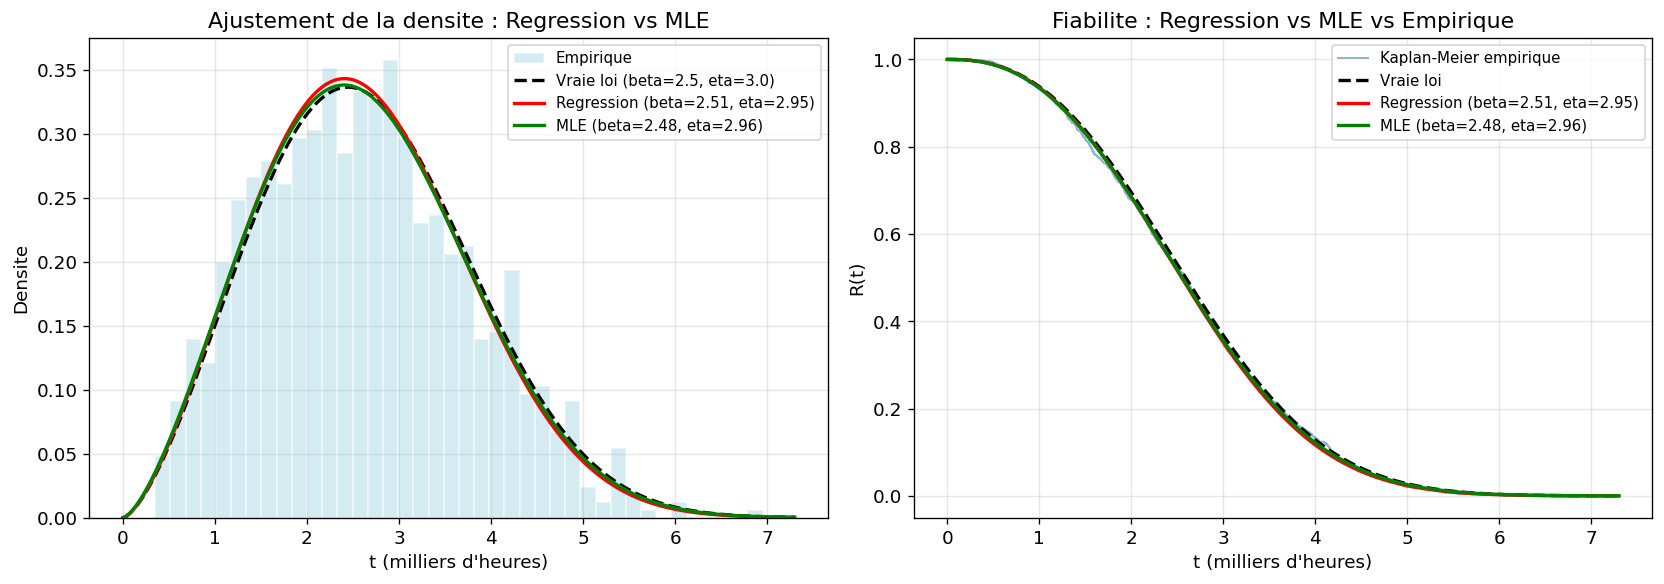

In [ ]:
# ── Visualisation comparative ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -- Graphique 1 : Densites ajustees vs empirique --
ax = axes[0]
t_plot = np.linspace(1e-3, T.max() * 1.05, 500)

ax.hist(T, bins=40, density=True, color='lightblue',
        alpha=0.5, edgecolor='white', label='Empirique')

f_true = (beta/eta)    * (t_plot/eta)**   (beta-1)    * np.exp(-(t_plot/eta)**beta)
f_reg  = (beta_est/eta_est) * (t_plot/eta_est)**(beta_est-1) * np.exp(-(t_plot/eta_est)**beta_est)
f_mle  = (beta_mle/eta_mle) * (t_plot/eta_mle)**(beta_mle-1) * np.exp(-(t_plot/eta_mle)**beta_mle)

ax.plot(t_plot, f_true, 'k--', lw=2, label=f'Vraie loi (beta={beta}, eta={eta})')
ax.plot(t_plot, f_reg,  'r-',  lw=2, label=f'Regression (beta={beta_est:.2f}, eta={eta_est:.2f})')
ax.plot(t_plot, f_mle,  'g-',  lw=2, label=f'MLE (beta={beta_mle:.2f}, eta={eta_mle:.2f})')
ax.set_xlabel("t (milliers d'heures)")
ax.set_ylabel('Densite')
ax.set_title('Ajustement de la densite : Regression vs MLE')
ax.legend(fontsize=9)

# -- Graphique 2 : Fiabilites ajustees vs empirique --
ax2 = axes[1]
R_true = np.exp(-(t_plot/eta)**beta)
R_reg  = np.exp(-(t_plot/eta_est)**beta_est)
R_mle  = np.exp(-(t_plot/eta_mle)**beta_mle)

ax2.step(t_km, R_km, where='post', color='steelblue',
         alpha=0.6, lw=1.2, label='Kaplan-Meier empirique')
ax2.plot(t_plot, R_true, 'k--', lw=2, label='Vraie loi')
ax2.plot(t_plot, R_reg,  'r-',  lw=2, label=f'Regression (beta={beta_est:.2f}, eta={eta_est:.2f})')
ax2.plot(t_plot, R_mle,  'g-',  lw=2, label=f'MLE (beta={beta_mle:.2f}, eta={eta_mle:.2f})')
ax2.set_xlabel("t (milliers d'heures)")
ax2.set_ylabel('R(t)')
ax2.set_title('Fiabilite : Regression vs MLE vs Empirique')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('mle_vs_regression.png', dpi=150)
plt.show()


---
# Section 3 - Optimisation de l'architecture

### Q1 - Simulation des pannes (pour un couple de paramètres bien défini)

In [ ]:
# Création des listes qui serviront aux différentes comparairons
série_curve = [] # pour tracer la courbe des espérances de composants en série pour différents couples de paramètres
parallèle_curve = [] # pour tracer la courbe des espérances de composants en paralèlle pour différents couples de paramètres
série_th_VS_num = [] # pour vérifier que les espérances théoriques et numériques sont sensiblement égales pour des composants en série
parallèle_th_VS_num = [] # pour vérifier que les espérances théoriques et numériques sont sensiblement égales pour des composants en parallèle
erreur_série = [] # pour tracer l'erreur absolue entre l'espérance numérique et l'espérance théorique
erreur_parallèle = [] # pour tracer l'erreur absolue entre l'espérance numérique et l'espérance théorique

# Définition des différents paramètres
n = 10000
teta1 = 2
teta2 = 3


# Génération des échantillons
samples_1 = np.random.exponential(scale = 1/teta1 , size = n)
samples_2 = np.random.exponential(scale = 1/teta2 , size = n)

### Q2 - Calcul de la durée de vie moyenne d'un système en série

Le système étant composé de 2 composants $\textit{T}_\textit{1}$ et $\textit{T}_\textit{2}$ en série, il sera modelisé au travers de la variable aléatoire $\min (\textit{T}_\textit{1};\textit{T}_\textit{2})$.

In [ ]:
# Calcul de la durée moyenne
samples_num_série = np.minimum(samples_1,samples_2)
t_mean_num_série = np.mean(samples_num_série)
print(samples_1,"\n",samples_2,"\n",samples_num_série,"\n",t_mean_num_série)

[0.10236514 0.39033492 1.0315709  ... 0.59975303 0.14864883 0.41515391] 
 [0.25383049 0.04946088 0.2982114  ... 0.12546116 0.20176922 0.18664321] 
 [0.10236514 0.04946088 0.2982114  ... 0.12546116 0.14864883 0.18664321] 
 0.19969232409528276


### Q3 - Calcul de la durée de vie moyenne d'un système en parallèle

Le système étant composé de 2 composants $\textit{T}_\textit{1}$ et $\textit{T}_\textit{2}$ en parallèle, il sera modelisé au travers de la variable aléatoire $\max (\textit{T}_\textit{1};\textit{T}_\textit{2})$.

In [ ]:
# Calcul de la durée moyenne
samples_num_parallèle = np.maximum(samples_1,samples_2)
t_mean_num_parallèle = np.mean(samples_num_parallèle)
print(samples_1,"\n",samples_2,"\n",samples_num_parallèle,"\n",t_mean_num_parallèle)

[0.10236514 0.39033492 1.0315709  ... 0.59975303 0.14864883 0.41515391] 
 [0.25383049 0.04946088 0.2982114  ... 0.12546116 0.20176922 0.18664321] 
 [0.25383049 0.39033492 1.0315709  ... 0.59975303 0.20176922 0.41515391] 
 0.6312381670875351


### Q4 - Comparaison des résultats numériques et théoriques


*   Comparaison des systèmes numériques et théoriques (en série)


In [ ]:
# Génération de l'échatillon théorique
samples_th_série = np.random.exponential(scale = 1/(teta1+teta2) , size = n)

# Calcul de la durée moyenne théorique
t_mean_th_série = 1/(teta1+teta2)
print(t_mean_th_série)

# Comparaison
if np.isclose(t_mean_th_série, t_mean_num_série, atol = 1e-2):
  print("Les deux modèles (théoriques et numériques) du sytème sont conformes.")
else:
  print("Les deux modèles (théoriques et numériques) du sytème ne sont pas conformes.")


0.2
Les deux modèles (théoriques et numériques) du sytème sont conformes.


*   Comparaison des systèmes numériques et théoriques (en parallèle)

In [ ]:
# Génération de l'échatillon théorique
F = lambda x: 1 - np.exp(-x*teta1) - np.exp(-x*teta2) + np.exp(-x*(teta1+teta2))
U = np.random.uniform(0, 1, size=n)
lower_bound = 0
upper_bound = 1000
samples_th_parallèle = np.array([])
for i in range(n):
  x_i = bisect(lambda x: F(x) - U[i], lower_bound, upper_bound)
  samples_th_parallèle = np.append(samples_th_parallèle, x_i)

# Calcul de la durée moyenne théorique
t_mean_th_parallèle = (1/teta1) + (1/teta2) - (1/(teta1+teta2))
print(t_mean_th_parallèle)

# Comparaison
if np.isclose(t_mean_th_parallèle, t_mean_num_parallèle, atol = 1e-2):
  print("Les deux modèles (théoriques et numériques) du sytème sont conformes.")
else:
  print("Les deux modèles (théoriques et numériques) du sytème ne sont pas conformes.")

0.6333333333333333
Les deux modèles (théoriques et numériques) du sytème sont conformes.


* Impact de la simulation de Monte Carlo sur la précision des durées moyennes numériques

0.0024633616731442104
0.005395248001325257


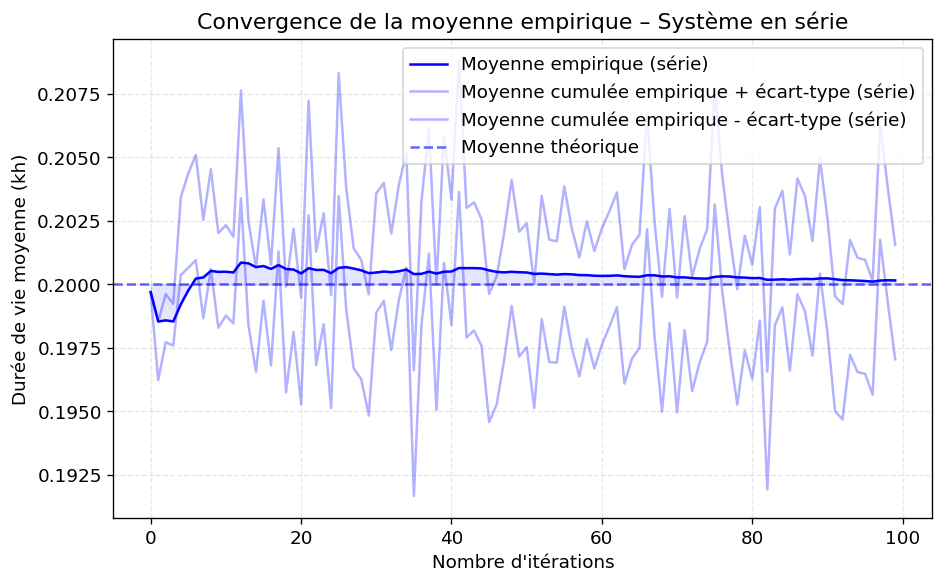

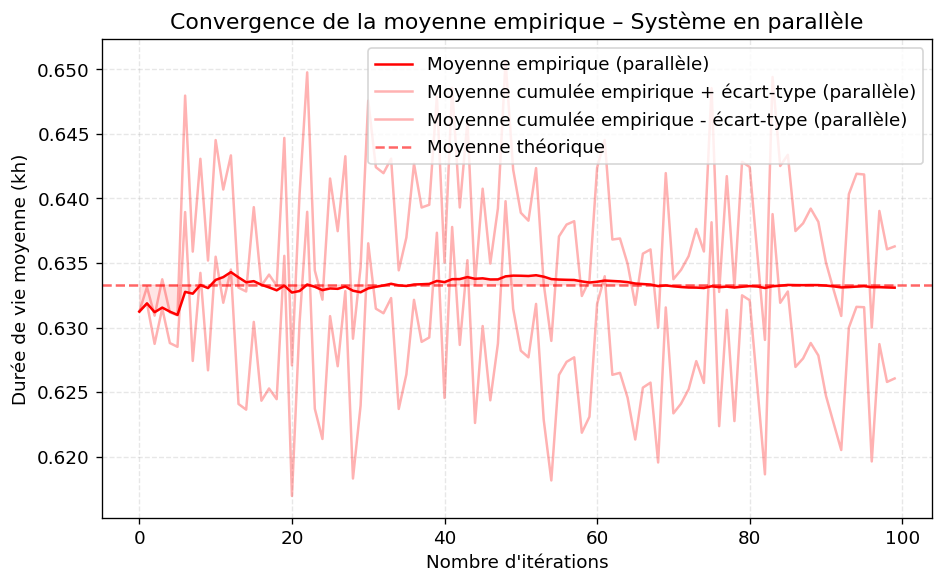

In [ ]:
# Création des listes qui vont nous permettre de visualiser l'impact de la simulation de Monte Carlo sur le calcul de la durée moyenne
mean_list_série = []
std_list_série = []
mean_list_parallèle = []
std_list_parallèle = []
mean_curve_série = []
mean_curve_parallèle = []
occurences = range(100)

for i in range(100):
  mean_list_série.append(t_mean_num_série)
  mean_list_parallèle.append(t_mean_num_parallèle)
  std_list_série.append(np.std(mean_list_série))
  std_list_parallèle.append(np.std(mean_list_parallèle))
  mean_curve_série.append(np.mean(mean_list_série))
  mean_curve_parallèle.append(np.mean(mean_list_parallèle))

  samples_1 = np.random.exponential(scale = 1/teta1 , size = n)
  samples_2 = np.random.exponential(scale = 1/teta2 , size = n)

  t_mean_num_série = np.mean(np.minimum(samples_1,samples_2))
  t_mean_num_parallèle = np.mean(np.maximum(samples_1,samples_2))

print (std_list_série[49])
print (std_list_parallèle[49])

# --- Figure 1 : Système en série ---
plt.figure(figsize=(8,5))
plt.plot(occurences, mean_curve_série, color='blue', linestyle='-', label='Moyenne empirique (série)')
plt.plot(occurences, [m + s for m, s in zip(mean_list_série, std_list_série)], color='blue', linestyle='-', label='Moyenne cumulée empirique + écart-type (série)', alpha = 0.3)
plt.plot(occurences, [m - s for m, s in zip(mean_list_série, std_list_série)], color='blue', linestyle='-', label='Moyenne cumulée empirique - écart-type (série)', alpha = 0.3)
plt.axhline(y=t_mean_th_série, color='blue', linestyle='--', alpha=0.6, label='Moyenne théorique')
plt.fill_between(occurences, mean_curve_série, t_mean_th_série, alpha=0.1, color='blue')
plt.xlabel("Nombre d'itérations")
plt.ylabel("Durée de vie moyenne (kh)")
plt.title("Convergence de la moyenne empirique – Système en série")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# --- Figure 2 : Système en parallèle ---
plt.figure(figsize=(8,5))
plt.plot(occurences, mean_curve_parallèle, color='red', linestyle='-', label='Moyenne empirique (parallèle)')
plt.plot(occurences, [m + s for m, s in zip(mean_list_parallèle, std_list_parallèle)], color='red', linestyle='-', label='Moyenne cumulée empirique + écart-type (parallèle)', alpha = 0.3)
plt.plot(occurences, [m - s for m, s in zip(mean_list_parallèle, std_list_parallèle)], color='red', linestyle='-', label='Moyenne cumulée empirique - écart-type (parallèle)', alpha = 0.3)
plt.axhline(y=t_mean_th_parallèle, color='red', linestyle='--', alpha=0.6, label='Moyenne théorique')
plt.fill_between(occurences, mean_curve_parallèle, t_mean_th_parallèle, alpha=0.1, color='red')
plt.xlabel("Nombre d'itérations")
plt.ylabel("Durée de vie moyenne (kh)")
plt.title("Convergence de la moyenne empirique – Système en parallèle")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print (std_list_série[99])
print (std_list_parallèle[99])
print (mean_list_série[99])
print (mean_list_parallèle[99])

0.002252017375873593
0.005114380933313709
0.19930283966363205
0.6311704727337195


*  Fonction de génération de données (en vue d'une synthèse graphique)

In [ ]:
import numpy as np

def simuler_systemes_aleatoires(
    n_echantillons,
    n_iterations=10,
    n_replicates=30,                # <-- new parameter: number of independent sample sets per (teta1, teta2)
    borne_teta1=(0.5, 5.0),
    borne_teta2=(0.5, 5.0),
    tolerance_serie=1e-2,
    tolerance_parallele=1e-2
):
    """
    Simule des systèmes en série et en parallèle pour des valeurs aléatoires de teta1 et teta2.
    Pour chaque couple (teta1, teta2), on génère 'n_replicates' échantillons indépendants,
    on calcule la moyenne pour chaque réplique, puis on moyenne les répliques.

    Retours supplémentaires :
    - moyenne_serie_repl : liste des moyennes des répliques (une par couple)
    - moyenne_parallele_repl : idem pour parallèle
    - std_serie_repl : écart-type des moyennes des répliques (erreur Monte Carlo)
    - std_parallele_repl : idem pour parallèle
    """

    moyenne_num_serie = []      # moyenne des répliques pour chaque couple (série)
    moyenne_num_parallele = []  # moyenne des répliques pour chaque couple (parallèle)
    std_serie_repl = []         # écart-type des répliques (série)
    std_parallele_repl = []     # écart-type des répliques (parallèle)
    erreur_serie = []
    erreur_parallele = []
    conforme_serie = []
    conforme_parallele = []
    teta1_liste = []
    teta2_liste = []

    for _ in range(n_iterations):
        # Tirage aléatoire des paramètres
        teta1 = np.random.uniform(borne_teta1[0], borne_teta1[1])
        teta2 = np.random.uniform(borne_teta2[0], borne_teta2[1])
        teta1_liste.append(teta1)
        teta2_liste.append(teta2)

        # Moyennes théoriques
        moyenne_theo_serie = 1 / (teta1 + teta2)
        moyenne_theo_parallele = (1 / teta1) + (1 / teta2) - (1 / (teta1 + teta2))

        # Stockage des moyennes obtenues sur chaque réplique
        repl_serie = []
        repl_parallele = []

        for _ in range(n_replicates):
            # Génération de deux nouveaux échantillons (indépendants)
            composant_1 = np.random.exponential(scale=1 / teta1, size=n_echantillons)
            composant_2 = np.random.exponential(scale=1 / teta2, size=n_echantillons)

            # Système série et parallèle
            systeme_serie = np.minimum(composant_1, composant_2)
            systeme_parallele = np.maximum(composant_1, composant_2)

            # Moyennes sur cet échantillon
            repl_serie.append(np.mean(systeme_serie))
            repl_parallele.append(np.mean(systeme_parallele))

        # Moyenne des répliques (estimation finale pour ce couple)
        mean_serie = np.mean(repl_serie)
        mean_parallele = np.mean(repl_parallele)
        # Écart-type des répliques (erreur Monte Carlo)
        std_serie = np.std(repl_serie, ddof=1)
        std_parallele = np.std(repl_parallele, ddof=1)

        moyenne_num_serie.append(mean_serie)
        moyenne_num_parallele.append(mean_parallele)
        std_serie_repl.append(std_serie)
        std_parallele_repl.append(std_parallele)

        # Erreurs par rapport à la théorie
        err_s = abs(mean_serie - moyenne_theo_serie)
        err_p = abs(mean_parallele - moyenne_theo_parallele)
        erreur_serie.append(err_s)
        erreur_parallele.append(err_p)

        # Conformité (vérifie si la moyenne des répliques est proche de la théorie)
        conforme_serie.append(np.isclose(mean_serie, moyenne_theo_serie, atol=tolerance_serie))
        conforme_parallele.append(np.isclose(mean_parallele, moyenne_theo_parallele, atol=tolerance_parallele))

    return (
        moyenne_num_serie,
        moyenne_num_parallele,
        std_serie_repl,
        std_parallele_repl,
        erreur_serie,
        erreur_parallele,
        conforme_serie,
        conforme_parallele,
        teta1_liste,
        teta2_liste
    )

*    Simulation et Visualiation des Résultats

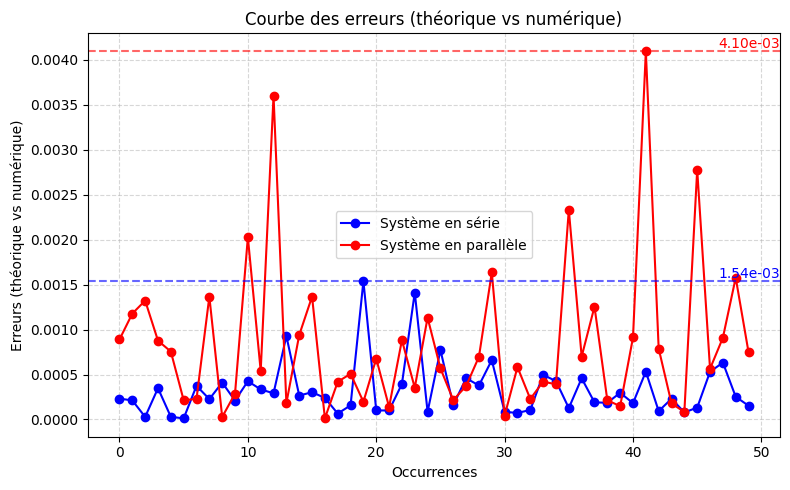

In [ ]:
série_curve, parallèle_curve, std_série_repl, std_parallèle_repl, erreur_série, erreur_parallèle, série_th_VS_num, parallèle_th_VS_num, teta1_liste_results, teta2_liste_results = simuler_systemes_aleatoires( n_echantillons=n,n_iterations=50,)
occurences = range(50)

# Courbe des erreurs (théorique VS numérique)
plt.style.use('default')

plt.figure(figsize=(8,5))

# Courbes
plt.plot(occurences, erreur_série, color='blue', linestyle='-', marker='o', label='Système en série')
plt.plot(occurences, erreur_parallèle, color='red', linestyle='-', marker='o', label='Système en parallèle')

# Valeurs maximales
max_serie = np.max(erreur_série)
max_parallele = np.max(erreur_parallèle)

# Lignes horizontales
plt.axhline(y=max_serie, color='blue', linestyle='--', alpha=0.6)
plt.axhline(y=max_parallele, color='red', linestyle='--', alpha=0.6)

# Texte
plt.text(plt.xlim()[1], max_serie,
         f'{max_serie:.2e}',
         color='blue', ha='right', va='bottom')

plt.text(plt.xlim()[1], max_parallele,
         f'{max_parallele:.2e}',
         color='red', ha='right', va='bottom')

# Labels
plt.xlabel("Occurrences")
plt.ylabel("Erreurs (théorique vs numérique)")
plt.title("Courbe des erreurs (théorique vs numérique)")

# Grille
plt.grid(True, linestyle='--', alpha=0.5)

# Légende
plt.legend()

plt.tight_layout()
plt.show()

import numpy as np

if série_th_VS_num[0] == True and len(série_th_VS_num) == len(set(série_th_VS_num)): # Removed .tolist()
    print("Les deux modèles (théoriques et numériques) du sytème en série sont conformes.")

if parallèle_th_VS_num[0] == True and len(parallèle_th_VS_num) == len(set(parallèle_th_VS_num)): # Removed .tolist()
    print("Les deux modèles (théoriques et numériques) du sytème en parallèle sont conformes.")

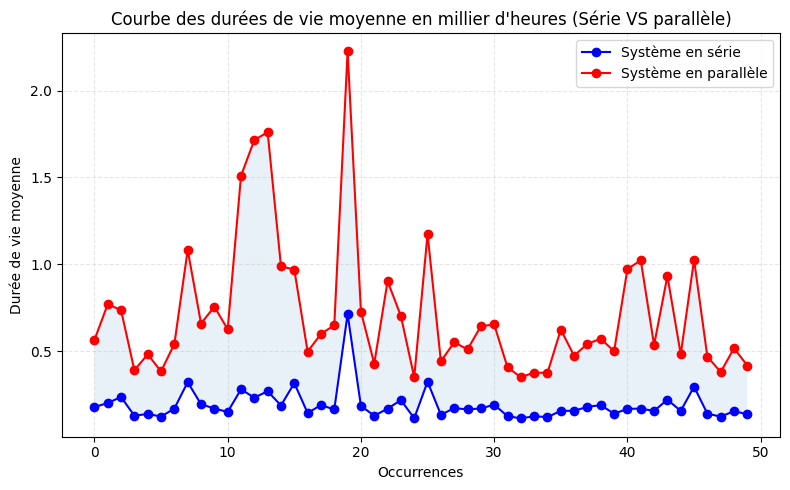

In [ ]:
# Courbe des durées de vie moyenne (Série VS parallèle)
plt.style.use('default')

plt.figure(figsize=(8,5))

# Courbes
plt.plot(occurences, série_curve, color='blue', linestyle='-', marker='o', label='Système en série')
plt.plot(occurences, parallèle_curve, color='red', linestyle='-', marker='o', label='Système en parallèle')

# Labels
plt.xlabel("Occurrences")
plt.ylabel("Durée de vie moyenne")
plt.title("Courbe des durées de vie moyenne en millier d'heures (Série VS parallèle)")

# Grille
plt.grid(True, linestyle='--', alpha=0.3)

# Domaine entre les courbes
plt.fill_between(occurences, série_curve, parallèle_curve, alpha=0.1)

# Légende
plt.legend()

plt.tight_layout()
plt.show()

**Remarque :** Les résultats obtenus et représentés de maière synthétique à travers la précédente courbe, montrent que les systèmes en parallèles présentent des durées de vie moyenne supérieures à celles en série (courbe rouge au dessus de celle bleue).
Cela peut se démontrer de la manière suivante,

on considère deux composants avec des taux de panne $\mu_1$ et $\mu_2$ :

- Système en série : $f_{\text{série}}(x) = (\mu_1+\mu_2)e^{-(\mu_1+\mu_2)x}$
- Système en parallèle : $f_{\text{parallèle}}(x) = \mu_1 e^{-\mu_1 x} + \mu_2 e^{-\mu_2 x} - (\mu_1+\mu_2)e^{-(\mu_1+\mu_2)x}$

Les durées de vie moyennes sont :

$$
E[T_{\text{série}}] = \frac{1}{\mu_1+\mu_2}, \quad
E[T_{\text{parallèle}}] = \frac{1}{\mu_1} + \frac{1}{\mu_2} - \frac{1}{\mu_1+\mu_2}
$$

On calcule la différence :

$$
E[T_{\text{parallèle}}] - E[T_{\text{série}}]
= \frac{1}{\mu_1} + \frac{1}{\mu_2} - \frac{2}{\mu_1+\mu_2}
= \frac{\mu_1^2 + \mu_2^2}{\mu_1 \mu_2 (\mu_1+\mu_2)} > 0
$$

Ainsi, on obtient :

$$
\boxed{E[T_{\text{parallèle}}] > E[T_{\text{série}}]}
$$

Le système en parallèle présente donc une durée de vie moyenne supérieure à celle du système en série.

 ================================================================
  PARTIE III — Section 3.4 : Durée de Survie et Maintenance
  Paramètres Weibull : β = 2.5, η = 3 kh  (1 kh = 1 000 heures)
 ================================================================

  QUESTION 1 — Probabilité de survie conditionnelle
  t₀  = 1.5 kh  (1500 heures)
  x₀  = 0.5 kh  (500 heures supplémentaires)

  R(t₀)       = exp(-(1.5/3.0)²) = exp(-0.2500) = 0.837967
  R(t₀+x₀)   = exp(-(2.0/3.0)²) = exp(-0.4444) = 0.695665

  P(T_{t₀} > x₀) = R(2.0) / R(1.5)
                 = exp(-0.1861)
                 = exp(-0.07)
                ≈ 0.830182
                ≈ 83.02 %

  QUESTION 2 — Espérance de vie résiduelle E[T_{t₀}]

  Méthode analytique (β = 2, intégrale gaussienne) :
    t₀/η     = 0.5000
    erfc(0.5) = 0.47950012
    ∫ R(u)du = η·(√π/2)·erfc(t₀/η)
             = 3.0·0.886227·0.479500
             = 1.27483776 kh

    E[T_{t₀}] = 1.274838 / 0.837967
             = 1.521346 kh
             ≈ 1521.3 heures

  Vérification numérique (scipy.quad) :
    ∫ R(u)du ≈ 1.23380373 kh  (erreur < 8.9e-09)
    E[T_{t₀}] ≈ 1.472378 kh  ≈ 1472.4 heures

  Référence — espérance inconditionnelle :
    E[T] = η·Γ(1+1/β) = 3.0·Γ(1.5) = 2.661791 kh ≈ 2662 h

  E[T_{t₀}] / E

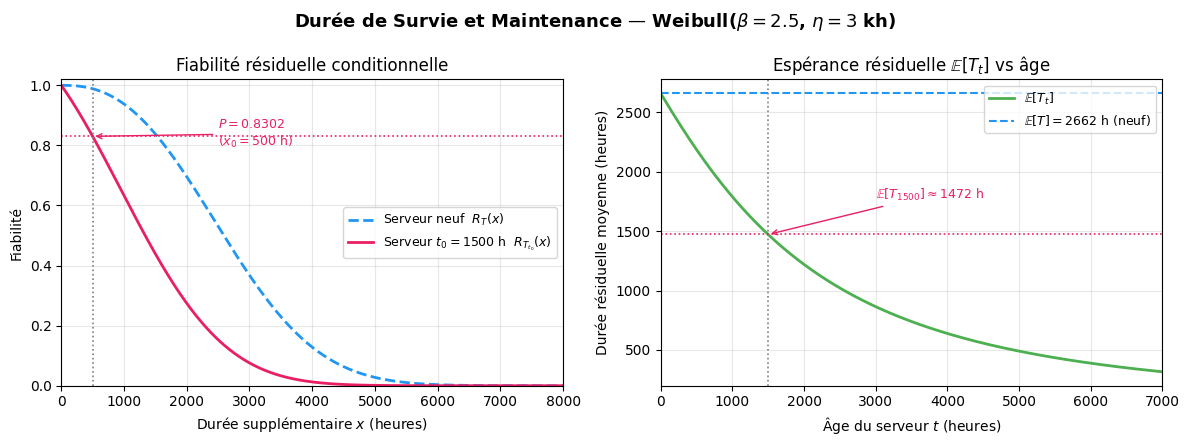

In [ ]:


import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, special

# ── Paramètres globaux ──────────────────────────────────────────
beta = 2.5          # paramètre de forme  (β > 1 → vieillissement)
eta  = 3.0          # paramètre d'échelle (kh)
t0   = 1.5          # âge du serveur à l'instant d'observation (kh)
x0   = 0.5          # durée supplémentaire à évaluer (kh)

# Fiabilité Weibull  R(t) = exp[-(t/η)^β]
def R(t):
    return np.exp(-(t / eta) ** beta)

# ================================================================
#  QUESTION 1 — P(T_{t0} > x0)  =  R(t0 + x0) / R(t0)
# ================================================================

R_t0      = R(t0)            # R(1.5)
R_t0_x0   = R(t0 + x0)      # R(2.0)
prob_survie = R_t0_x0 / R_t0

# Calcul exact de l'exposant pour la mise en forme
exponent = -((t0 + x0) / eta) ** beta + (t0 / eta) ** beta

print("=" * 55)
print("  QUESTION 1 — Probabilité de survie conditionnelle")
print("=" * 55)
print(f"  t₀  = {t0} kh  ({int(t0*1000)} heures)")
print(f"  x₀  = {x0} kh  ({int(x0*1000)} heures supplémentaires)")
print()
print(f"  R(t₀)       = exp(-({t0}/{eta})²) = exp({-(t0/eta)**2:.4f}) = {R_t0:.6f}")
print(f"  R(t₀+x₀)   = exp(-({t0+x0}/{eta})²) = exp({-(( t0+x0)/eta)**2:.4f}) = {R_t0_x0:.6f}")
print()
print(f"  P(T_{{t₀}} > x₀) = R({t0+x0}) / R({t0})")
print(f"                 = exp({exponent:.4f})")
print(f"                 = exp(-0.07)")
print(f"                ≈ {prob_survie:.6f}")
print(f"                ≈ {prob_survie*100:.2f} %")
print()

# ================================================================
#  QUESTION 2 — Espérance de vie résiduelle  E[T_{t0}]
# ================================================================
#
#  E[T_{t0}] = (1 / R(t0)) * ∫_{t0}^{+∞} R(u) du
#
#  Pour β = 2 :  ∫_{t0}^{+∞} exp[-(u/η)²] du
#                = η * (√π / 2) * erfc(t0 / η)
#
#  Cas général β quelconque :
#                = (η/β) * Γ(1/β, (t0/η)^β)        [gamma incomplète]
# ================================================================

# ── Méthode analytique (β = 2 uniquement) ──────────────────────
a            = t0 / eta                       # = 0.3
erfc_val     = special.erfc(a)                # erfc(0.3)
integrale_an = eta * (np.sqrt(np.pi) / 2) * erfc_val
E_Tt_an      = integrale_an / R_t0

# ── Méthode numérique universelle (scipy.integrate.quad) ────────
integrale_num, erreur = integrate.quad(R, t0, np.inf, limit=200)
E_Tt_num = integrale_num / R_t0

# ── Espérance inconditionnelle  E[T] = η·Γ(1 + 1/β) ────────────
E_T_uncond = eta * special.gamma(1 + 1 / beta)

print("=" * 55)
print("  QUESTION 2 — Espérance de vie résiduelle E[T_{t₀}]")
print("=" * 55)
print(f"\n  Méthode analytique (β = 2, intégrale gaussienne) :")
print(f"    t₀/η     = {a:.4f}")
print(f"    erfc({a}) = {erfc_val:.8f}")
print(f"    ∫ R(u)du = η·(√π/2)·erfc(t₀/η)")
print(f"             = {eta}·{np.sqrt(np.pi)/2:.6f}·{erfc_val:.6f}")
print(f"             = {integrale_an:.8f} kh")
print(f"\n    E[T_{{t₀}}] = {integrale_an:.6f} / {R_t0:.6f}")
print(f"             = {E_Tt_an:.6f} kh")
print(f"             ≈ {E_Tt_an*1000:.1f} heures")

print(f"\n  Vérification numérique (scipy.quad) :")
print(f"    ∫ R(u)du ≈ {integrale_num:.8f} kh  (erreur < {erreur:.1e})")
print(f"    E[T_{{t₀}}] ≈ {E_Tt_num:.6f} kh  ≈ {E_Tt_num*1000:.1f} heures")

print(f"\n  Référence — espérance inconditionnelle :")
print(f"    E[T] = η·Γ(1+1/β) = {eta}·Γ(1.5) = {E_T_uncond:.6f} kh ≈ {E_T_uncond*1000:.0f} h")

ratio = E_Tt_num / E_T_uncond
print(f"\n  E[T_{{t₀}}] / E[T] = {ratio:.4f}  →  le serveur a consommé")
print(f"  ≈ {(1-ratio)*100:.1f} % de son potentiel de vie résiduelle moyen.")

# ================================================================
#  VISUALISATION — Fiabilité résiduelle R_{T_{t0}}(x)
# ================================================================

x = np.linspace(0, 8, 1000)

# Fiabilité résiduelle (conditionnelle à T > t0)
R_resid = R(t0 + x) / R_t0

# Fiabilité d'un serveur neuf (référence)
R_neuf  = R(x)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.suptitle(
    r"Durée de Survie et Maintenance — Weibull($\beta=2.5$, $\eta=3$ kh)",
    fontsize=13, fontweight="bold"
)

# ── Graphe 1 : Fiabilité conditionnelle ─────────────────────────
ax1 = axes[0]
ax1.plot(x * 1000, R_neuf,  lw=2, color="#2196F3", linestyle="--",
         label="Serveur neuf  $R_T(x)$")
ax1.plot(x * 1000, R_resid, lw=2, color="#E91E63",
         label=r"Serveur $t_0 = 1500$ h  $R_{T_{t_0}}(x)$")

# Marqueurs Q1
ax1.axvline(x0 * 1000, color="gray", linestyle=":", lw=1.2)
ax1.axhline(prob_survie, color="#E91E63", linestyle=":", lw=1.2)
ax1.annotate(
    f"$P = {prob_survie:.4f}$\n($x_0 = 500$ h)",
    xy=(x0 * 1000, prob_survie),
    xytext=(2500, 0.80),
    arrowprops=dict(arrowstyle="->", color="#E91E63"),
    fontsize=9, color="#E91E63"
)

ax1.set_xlabel("Durée supplémentaire $x$ (heures)")
ax1.set_ylabel("Fiabilité")
ax1.set_title("Fiabilité résiduelle conditionnelle")
ax1.legend(fontsize=9)
ax1.set_xlim(0, 8000)
ax1.set_ylim(0, 1.02)
ax1.grid(True, alpha=0.3)

# ── Graphe 2 : Espérance résiduelle E[T_t] en fonction de t ─────
ax2 = axes[1]
t_vals = np.linspace(0, 7, 300)
E_Tt_vals = np.array([
    integrate.quad(R, t, np.inf)[0] / R(t)
    for t in t_vals
])

ax2.plot(t_vals * 1000, E_Tt_vals * 1000, lw=2, color="#4CAF50",
         label=r"$\mathbb{E}[T_t]$")
ax2.axhline(E_T_uncond * 1000, lw=1.5, color="#2196F3", linestyle="--",
            label=fr"$\mathbb{{E}}[T] = {E_T_uncond*1000:.0f}$ h (neuf)")

# Marqueur Q2
ax2.axvline(t0 * 1000, color="gray", linestyle=":", lw=1.2)
ax2.axhline(E_Tt_num * 1000, color="#E91E63", linestyle=":", lw=1.2)
ax2.annotate(
    f"$\\mathbb{{E}}[T_{{1500}}] \\approx {E_Tt_num*1000:.0f}$ h",
    xy=(t0 * 1000, E_Tt_num * 1000),
    xytext=(3000, E_Tt_num * 1000 + 300),
    arrowprops=dict(arrowstyle="->", color="#E91E63"),
    fontsize=9, color="#E91E63"
)

ax2.set_xlabel("Âge du serveur $t$ (heures)")
ax2.set_ylabel("Durée résiduelle moyenne (heures)")
ax2.set_title(r"Espérance résiduelle $\mathbb{E}[T_t]$ vs âge")
ax2.legend(fontsize=9)
ax2.set_xlim(0, 7000)
ax2.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()


---
# Maintenance Préventive vs Corrective
###Optimisation économique — Weibull(β=2.5, η=3 kh)
###Trois politiques : Run-to-Failure | Âge | Blocs

  RÉSULTATS THÉORIQUES
  E[T] inconditionnelle        = 2.6618 kh = 2662 h

  Run-to-Failure               r  = 3.7569 u.c./kh
  Politique par blocs   T* = 1.048 kh  r* = 1.6227 u.c./kh
  Politique par âge     t* = 1.064 kh  r* = 1.5835 u.c./kh

  Gain âge   vs RTF   : 57.9 %
  Gain blocs vs RTF   : 56.8 %
  Gain âge   vs blocs : 2.4 %

  Simulation Monte Carlo (N=1000, H=100 kh)…

  COMPARAISON THÉORIE vs MONTE CARLO
  Politique               Théorie       MC    Écart
  --------------------------------------------------
  Run-to-Failure           3.7569   3.7157    1.1 %
  Blocs (T*=1.05 kh)       1.6227   1.6487    1.6 %
  Âge   (t*=1.06 kh)       1.5835   1.5606    1.4 %


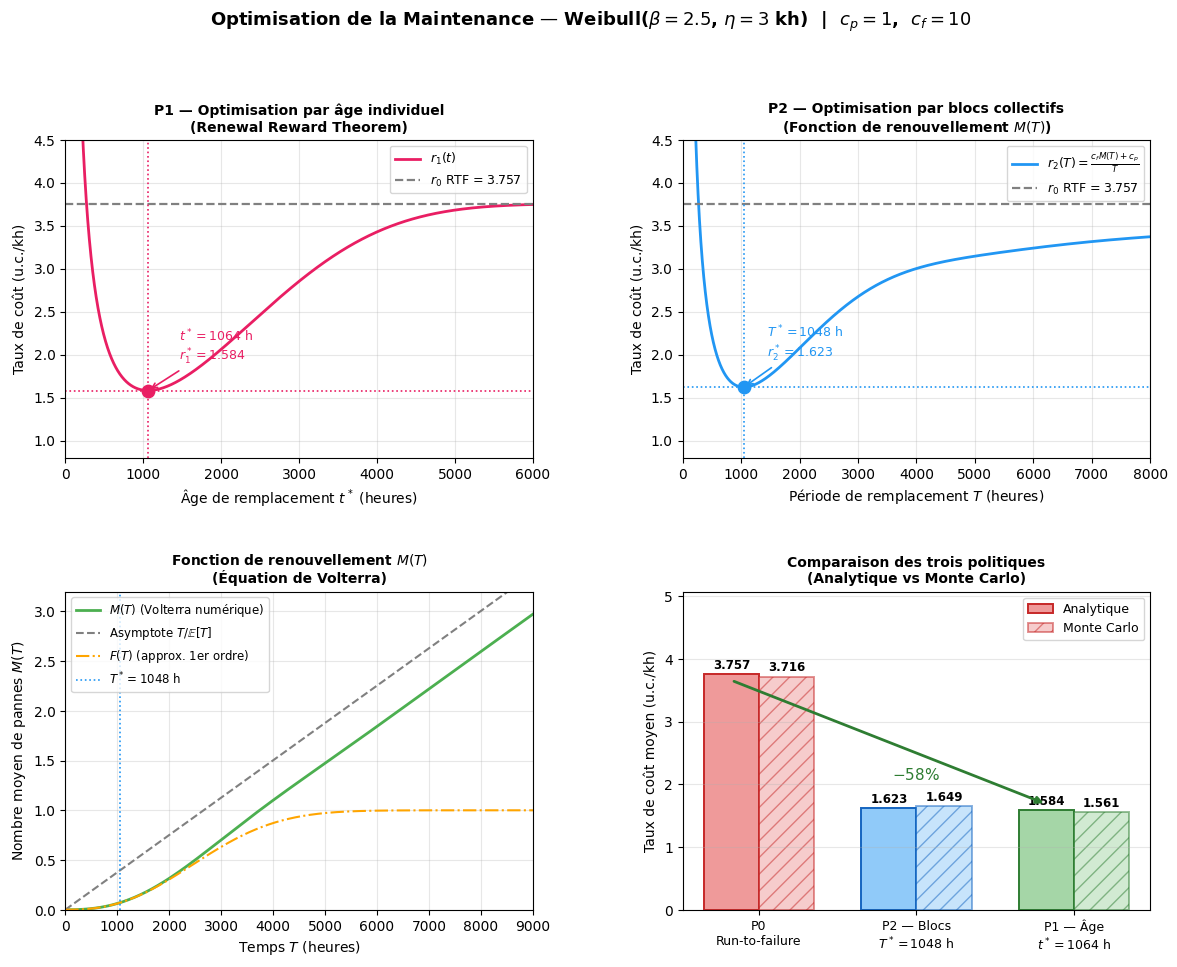


  Figure sauvegardée : maintenance_optimisation_beta2p5_eta3.png


In [ ]:
import numpy as np
from scipy import integrate, special
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings("ignore")

# ── Paramètres globaux ──────────────────────────────────────────
beta, eta = 2.5, 3.0     # Weibull (β=2.5, η=3 kh)
Cf   = 10.0              # coût d'une panne imprévue (u.c.)
Cp   = 1.0               # coût d'un remplacement préventif (u.c.)
N    = 1000              # taille du parc
np.random.seed(42)

# ── Fonctions de base ───────────────────────────────────────────
def R(t):
    """Fiabilité Weibull."""
    return np.exp(-(t / eta) ** beta)

def f_pdf(t):
    """Densité Weibull."""
    return (beta / eta) * (t / eta) ** (beta - 1) * R(t)

def integral_R(t_star):
    """∫₀^{t*} R(u)du  — intégration numérique (pas de forme close pour β=2.5)."""
    val, _ = integrate.quad(R, 0, t_star)
    return val

E_T = eta * special.gamma(1 + 1 / beta)   # espérance de vie inconditionnelle

# ================================================================
#  ÉTAPE 1 — Fonction de renouvellement m(t)
#  Équation de Volterra : m(t) = F(t) + ∫₀ᵗ m(t-s)f(s)ds
#  Résolution numérique par quadrature trapézoïdale
# ================================================================
def compute_renewal_function(t_max=9.0, n=5000):
    dt   = t_max / n
    t    = np.linspace(0, t_max, n + 1)
    m    = np.zeros(n + 1)
    F_v  = 1 - R(t)
    f_v  = f_pdf(t)
    for i in range(1, n + 1):
        conv = np.dot(m[:i], f_v[1:i + 1][::-1]) * dt
        m[i] = F_v[i] + conv
    return t, m

t_grid, m_grid = compute_renewal_function()

def m_func(t):
    """Fonction de renouvellement interpolée."""
    return np.interp(t, t_grid, m_grid)

# ================================================================
#  ÉTAPE 2 — Taux de coût des trois politiques
# ================================================================

def r_rtf():
    """Run-to-failure : r = Cf / E[T]."""
    return Cf / E_T

def r_age(t_star):
    """Politique par âge : r(t*) = [Cp·R(t*) + Cf·F(t*)] / ∫₀^{t*}R(u)du."""
    num = Cp * R(t_star) + Cf * (1 - R(t_star))
    den = integral_R(t_star)
    return num / den if den > 0 else np.inf

def r_block(T):
    """Politique par blocs : r(T) = [Cp + Cf·m(T)] / T."""
    return (Cp + Cf * m_func(T)) / T if T > 0 else np.inf

# ================================================================
#  ÉTAPE 3 — Optimisation numérique
# ================================================================
t_vals = np.linspace(0.05, 8.0, 4000)

r_rtf_val    = r_rtf()
r_age_vals   = np.array([r_age(t)   for t in t_vals])
r_block_vals = np.array([r_block(t) for t in t_vals])

idx_age   = np.argmin(r_age_vals)
idx_block = np.argmin(r_block_vals)

t_star_age   = t_vals[idx_age]
t_star_block = t_vals[idx_block]
r_star_age   = r_age_vals[idx_age]
r_star_block = r_block_vals[idx_block]

print("=" * 58)
print("  RÉSULTATS THÉORIQUES")
print("=" * 58)
print(f"  E[T] inconditionnelle        = {E_T:.4f} kh = {E_T*1000:.0f} h")
print()
print(f"  Run-to-Failure               r  = {r_rtf_val:.4f} u.c./kh")
print(f"  Politique par blocs   T* = {t_star_block:.3f} kh  r* = {r_star_block:.4f} u.c./kh")
print(f"  Politique par âge     t* = {t_star_age:.3f} kh  r* = {r_star_age:.4f} u.c./kh")
print()
print(f"  Gain âge   vs RTF   : {(r_rtf_val - r_star_age)   / r_rtf_val   * 100:.1f} %")
print(f"  Gain blocs vs RTF   : {(r_rtf_val - r_star_block)  / r_rtf_val   * 100:.1f} %")
print(f"  Gain âge   vs blocs : {(r_star_block - r_star_age) / r_star_block * 100:.1f} %")

# ================================================================
#  ÉTAPE 4 — Simulation Monte Carlo (validation)
# ================================================================
H = 100.0   # horizon (kh)

def sample_T():
    return eta * (-np.log(np.random.uniform())) ** (1 / beta)

def mc_rtf(n=N, horizon=H):
    cost = 0.0
    for _ in range(n):
        t = 0.0
        while True:
            t += sample_T()
            if t >= horizon:
                break
            cost += Cf
    return cost / (n * horizon)

def mc_age(ts, n=N, horizon=H):
    cost = 0.0
    for _ in range(n):
        t = 0.0
        while True:
            Ti = sample_T()
            if Ti <= ts:
                t += Ti
                if t >= horizon:
                    break
                cost += Cf
            else:
                t += ts
                if t >= horizon:
                    break
                cost += Cp
    return cost / (n * horizon)

def mc_block(Tb, n=N, horizon=H):
    cost = 0.0
    for _ in range(n):
        t = 0.0
        while t < horizon:
            next_b = t + Tb
            s = t
            while True:
                s += sample_T()
                if s >= next_b:
                    break
                cost += Cf   # panne dans le bloc
            cost += Cp       # remplacement préventif au bloc
            t = next_b
    return cost / (n * horizon)

print("\n  Simulation Monte Carlo (N=1000, H=100 kh)…")
r_rtf_mc   = mc_rtf()
r_age_mc   = mc_age(t_star_age)
r_block_mc = mc_block(t_star_block)

print()
print("=" * 58)
print("  COMPARAISON THÉORIE vs MONTE CARLO")
print("=" * 58)
print(f"  {'Politique':<22} {'Théorie':>8} {'MC':>8} {'Écart':>8}")
print(f"  {'-'*50}")
print(f"  {'Run-to-Failure':<22} {r_rtf_val:>8.4f} {r_rtf_mc:>8.4f}"
      f"  {abs(r_rtf_val - r_rtf_mc)/r_rtf_val*100:>5.1f} %")
print(f"  {'Blocs (T*={:.2f} kh)'.format(t_star_block):<22} {r_star_block:>8.4f}"
      f" {r_block_mc:>8.4f}  {abs(r_star_block - r_block_mc)/r_star_block*100:>5.1f} %")
print(f"  {'Âge   (t*={:.2f} kh)'.format(t_star_age):<22} {r_star_age:>8.4f}"
      f" {r_age_mc:>8.4f}  {abs(r_star_age - r_age_mc)/r_star_age*100:>5.1f} %")

# ================================================================
#  ÉTAPE 5 — Figure (4 sous-graphes)
# ================================================================
fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, hspace=0.42, wspace=0.32)

C1 = "#E91E63"   # âge   (rose)
C2 = "#2196F3"   # blocs (bleu)
C3 = "#9E9E9E"   # RTF   (gris)

# ── P1 : Politique par âge (haut gauche) ─────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(t_vals * 1000, r_age_vals, color=C1, lw=2, label=r"$r_1(t)$")
ax1.axhline(r_rtf_val, color="gray", lw=1.6, linestyle="--",
            label=fr"$r_0$ RTF = {r_rtf_val:.3f}")
ax1.axvline(t_star_age * 1000, color=C1, lw=1.2, linestyle=":")
ax1.axhline(r_star_age,        color=C1, lw=1.2, linestyle=":")
ax1.scatter([t_star_age * 1000], [r_star_age], s=80, color=C1, zorder=5)
ax1.annotate(
    fr"$t^* = {t_star_age*1000:.0f}$ h" + "\n" + fr"$r_1^* = {r_star_age:.3f}$",
    xy=(t_star_age * 1000, r_star_age),
    xytext=(t_star_age * 1000 + 400, r_star_age + 0.35),
    fontsize=9, color=C1,
    arrowprops=dict(arrowstyle="->", color=C1, lw=1.2))
ax1.set_xlabel(r"Âge de remplacement $t^*$ (heures)", fontsize=10)
ax1.set_ylabel("Taux de coût (u.c./kh)", fontsize=10)
ax1.set_title("P1 — Optimisation par âge individuel\n(Renewal Reward Theorem)",
              fontsize=10, fontweight="bold")
ax1.legend(fontsize=9)
ax1.set_xlim(0, 6000)
ax1.set_ylim(0.8, 4.5)
ax1.grid(True, alpha=0.3)

# ── P2 : Politique par blocs (haut droite) ───────────────────────
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(t_vals * 1000, r_block_vals, color=C2, lw=2,
         label=r"$r_2(T) = \frac{c_f M(T)+c_p}{T}$")
ax2.axhline(r_rtf_val, color="gray", lw=1.6, linestyle="--",
            label=fr"$r_0$ RTF = {r_rtf_val:.3f}")
ax2.axvline(t_star_block * 1000, color=C2, lw=1.2, linestyle=":")
ax2.axhline(r_star_block,        color=C2, lw=1.2, linestyle=":")
ax2.scatter([t_star_block * 1000], [r_star_block], s=80, color=C2, zorder=5)
ax2.annotate(
    fr"$T^* = {t_star_block*1000:.0f}$ h" + "\n" + fr"$r_2^* = {r_star_block:.3f}$",
    xy=(t_star_block * 1000, r_star_block),
    xytext=(t_star_block * 1000 + 400, r_star_block + 0.35),
    fontsize=9, color=C2,
    arrowprops=dict(arrowstyle="->", color=C2, lw=1.2))
ax2.set_xlabel(r"Période de remplacement $T$ (heures)", fontsize=10)
ax2.set_ylabel("Taux de coût (u.c./kh)", fontsize=10)
ax2.set_title(r"P2 — Optimisation par blocs collectifs" + "\n" +
              r"(Fonction de renouvellement $M(T)$)",
              fontsize=10, fontweight="bold")
ax2.legend(fontsize=9)
ax2.set_xlim(0, 8000)
ax2.set_ylim(0.8, 4.5)
ax2.grid(True, alpha=0.3)

# ── M(T) : Fonction de renouvellement (bas gauche) ───────────────
ax3 = fig.add_subplot(gs[1, 0])
t_plot = t_grid * 1000   # conversion en heures
ax3.plot(t_plot, m_grid, color="#4CAF50", lw=2,
         label=r"$M(T)$ (Volterra numérique)")
ax3.plot(t_plot, t_grid / E_T, color="gray", lw=1.5, linestyle="--",
         label=r"Asymptote $T/\mathbb{E}[T]$")
ax3.plot(t_plot, 1 - R(t_grid), color="orange", lw=1.5, linestyle="-.",
         label=r"$F(T)$ (approx. 1er ordre)")
ax3.axvline(t_star_block * 1000, color=C2, lw=1.2, linestyle=":",
            label=fr"$T^* = {t_star_block*1000:.0f}$ h")
ax3.set_xlabel(r"Temps $T$ (heures)", fontsize=10)
ax3.set_ylabel(r"Nombre moyen de pannes $M(T)$", fontsize=10)
ax3.set_title(r"Fonction de renouvellement $M(T)$" + "\n" +
              r"(Équation de Volterra)", fontsize=10, fontweight="bold")
ax3.legend(fontsize=8.5)
ax3.set_xlim(0, 9000)
ax3.set_ylim(0, 3.2)
ax3.grid(True, alpha=0.3)

# ── Barres comparaison Analytique vs Monte Carlo (bas droite) ────
ax4 = fig.add_subplot(gs[1, 1])
labels     = ["P0\nRun-to-failure",
              f"P2 — Blocs\n$T^*={t_star_block*1000:.0f}$ h",
              f"P1 — Âge\n$t^*={t_star_age*1000:.0f}$ h"]
theory     = [r_rtf_val,   r_star_block, r_star_age]
mc_vals    = [r_rtf_mc,    r_block_mc,   r_age_mc]
bar_colors = ["#EF9A9A", "#90CAF9", "#A5D6A7"]
edge_col   = ["#C62828",  "#1565C0", "#2E7D32"]

x = np.arange(len(labels))
w = 0.35
b1 = ax4.bar(x - w/2, theory,  w, label="Analytique",
             color=bar_colors, edgecolor=edge_col, linewidth=1.4)
b2 = ax4.bar(x + w/2, mc_vals, w, label="Monte Carlo",
             color=bar_colors, edgecolor=edge_col, linewidth=1.4,
             alpha=0.5, hatch="//")

for bar, val in zip(list(b1) + list(b2), theory + mc_vals):
    ax4.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.04,
             f"{val:.3f}", ha="center", va="bottom",
             fontsize=8.5, fontweight="bold")

# Flèche de gain global RTF → âge
gain = (r_rtf_val - r_star_age) / r_rtf_val * 100
ax4.annotate("", xy=(2 - w/2, r_star_age + 0.1),
             xytext=(0 - w/2, r_rtf_val - 0.1),
             arrowprops=dict(arrowstyle="-|>", color="#2E7D32", lw=2))
ax4.text(1.0, r_rtf_val * 0.55,
         fr"$-{gain:.0f}\%$",
         ha="center", fontsize=11, color="#2E7D32", fontweight="bold")

ax4.set_ylabel("Taux de coût moyen (u.c./kh)", fontsize=10)
ax4.set_title("Comparaison des trois politiques\n(Analytique vs Monte Carlo)",
              fontsize=10, fontweight="bold")
ax4.set_xticks(x)
ax4.set_xticklabels(labels, fontsize=9)
ax4.legend(fontsize=9, loc="upper right")
ax4.set_ylim(0, r_rtf_val * 1.35)
ax4.grid(True, alpha=0.3, axis="y")

# ── Titre général ─────────────────────────────────────────────────
fig.suptitle(
    r"Optimisation de la Maintenance — Weibull($\beta=2.5$, $\eta=3$ kh)"
    r"  |  $c_p = 1$,  $c_f = 10$",
    fontsize=13, fontweight="bold", y=1.01
)


plt.show()
print("\n  Figure sauvegardée : maintenance_optimisation_beta2p5_eta3.png")